In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import shutil
import random

random.seed(42)

base = "/content/drive/MyDrive/dog_cat_dataset/dog_cat"

In [4]:
classes = ["cat", "dog"]

splits = ["train", "valid", "test"]

# Create classification folders
for split in splits:
    for cls in classes:
        os.makedirs(
            os.path.join(base, split, cls),
            exist_ok=True
        )

# Move images from train/cat and train/dog
for cls in classes:

    source = os.path.join(base, "train", cls)

    if not os.path.exists(source):
        continue

    images = [
        f for f in os.listdir(source)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    random.shuffle(images)

    total = len(images)

    train_end = int(total * 0.70)
    valid_end = int(total * 0.85)

    train_images = images[:train_end]
    valid_images = images[train_end:valid_end]
    test_images = images[valid_end:]

    datasets = {
        "train": train_images,
        "valid": valid_images,
        "test": test_images
    }

    for split, files in datasets.items():

        destination = os.path.join(
            base, split, cls
        )

        for file in files:

            shutil.move(
                os.path.join(source, file),
                os.path.join(destination, file)
            )

print("Dataset organized successfully!")

Dataset organized successfully!


In [5]:
for split in ["train", "valid", "test"]:

    print("\n", split.upper())

    for cls in classes:

        folder = os.path.join(base, split, cls)

        print(cls, ":", len(os.listdir(folder)))


 TRAIN
cat : 350
dog : 350

 VALID
cat : 75
dog : 75

 TEST
cat : 75
dog : 75


In [7]:
!pip install ultralytics
from ultralytics import YOLO

# Load classification model
model = YOLO("yolov8n-cls.pt")

# Train model
results = model.train(
    data=base,
    epochs=20,
    imgsz=224,
    batch=16,
    name="dog_cat_classifier"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 21.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dog_cat_dataset/dog_cat, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1

In [8]:
metrics = model.val()

print(metrics)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 3.3 GFLOPs
train: /content/drive/MyDrive/dog_cat_dataset/dog_cat/train... found 1700 images in 3/4 classes ✅ 
val: /content/drive/MyDrive/dog_cat_dataset/dog_cat/valid... found 150 images in 2/4 classes ✅ 
test: /content/drive/MyDrive/dog_cat_dataset/dog_cat/test... found 150 images in 2/4 classes ✅ 
WARNING ⚠️ val: Slow image access detected (ping: 2.3±1.5 ms, read: 3.9±3.8 MB/s, size: 24.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/dog_cat_dataset/dog_cat/valid... 150 images, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 7.3Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 10/10 2.1it/s 4.8s
                   all      0.253          1
Speed: 0.0ms preprocess, 16.9ms inference, 

In [13]:
!pip install opencv-python matplotlib
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
metrics = model.val()

print(metrics)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 3.3 GFLOPs
train: /content/drive/MyDrive/dog_cat_dataset/dog_cat/train... found 1700 images in 3/4 classes ✅ 
val: /content/drive/MyDrive/dog_cat_dataset/dog_cat/valid... found 150 images in 2/4 classes ✅ 
test: /content/drive/MyDrive/dog_cat_dataset/dog_cat/test... found 150 images in 2/4 classes ✅ 
WARNING ⚠️ val: Slow image access detected (ping: 1.1±0.9 ms, read: 15.1±3.3 MB/s, size: 24.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/dog_cat_dataset/dog_cat/valid... 150 images, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 23.3Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 10/10 2.1it/s 4.7s
                   all      0.253          1
Speed: 0.0ms preprocess, 16.6ms inference

In [15]:
model = YOLO(
    "runs/classify/dog_cat_classifier/weights/best.pt"
)

results = model.predict(
    source=os.path.join(base, "test", "cat"),
    save=True,
    conf=0.25
)


image 1/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4015.jpg: 224x224 cat 0.58, images 0.41, dog 0.01, labels 0.00, 21.3ms
image 2/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4017.jpg: 224x224 images 0.61, cat 0.35, dog 0.05, labels 0.00, 16.7ms
image 3/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4020.jpg: 224x224 images 0.57, cat 0.40, dog 0.03, labels 0.00, 13.8ms
image 4/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4021.jpg: 224x224 images 0.52, cat 0.45, dog 0.03, labels 0.00, 16.2ms
image 5/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4042.jpg: 224x224 images 0.55, dog 0.28, cat 0.17, labels 0.00, 22.9ms
image 6/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4045.jpg: 224x224 cat 0.60, images 0.39, dog 0.01, labels 0.00, 22.9ms
image 7/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/cat/cat.4056.jpg: 224x224 images 0.64, cat 0.19, dog 0.16, labels 0.00, 22.2ms
image

In [16]:
results = model.predict(
    source=os.path.join(base, "test", "dog"),
    save=True,
    conf=0.25
)


image 1/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4002.jpg: 224x224 images 0.63, dog 0.33, cat 0.04, labels 0.00, 56.6ms
image 2/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4004.jpg: 224x224 images 0.52, dog 0.47, cat 0.01, labels 0.00, 45.5ms
image 3/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4005.jpg: 224x224 dog 0.52, images 0.45, cat 0.03, labels 0.00, 23.3ms
image 4/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4010.jpg: 224x224 images 0.54, dog 0.45, cat 0.01, labels 0.00, 22.0ms
image 5/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4012.jpg: 224x224 images 0.59, dog 0.30, cat 0.10, labels 0.00, 73.1ms
image 6/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4027.jpg: 224x224 images 0.62, dog 0.38, cat 0.00, labels 0.00, 24.0ms
image 7/75 /content/drive/MyDrive/dog_cat_dataset/dog_cat/test/dog/dog.4032.jpg: 224x224 dog 0.58, images 0.40, cat 0.02, labels 0.00, 23.0ms
image

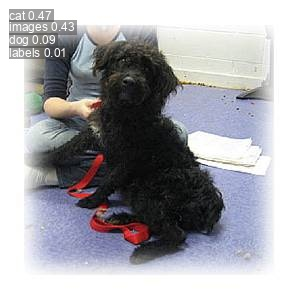

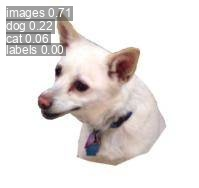

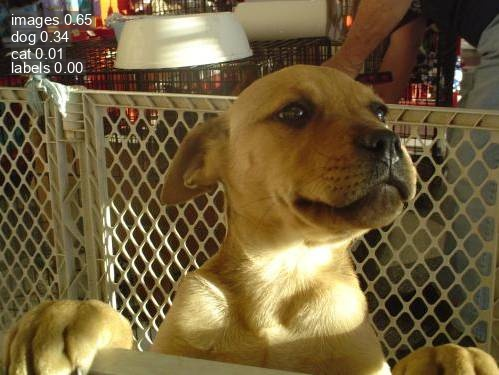

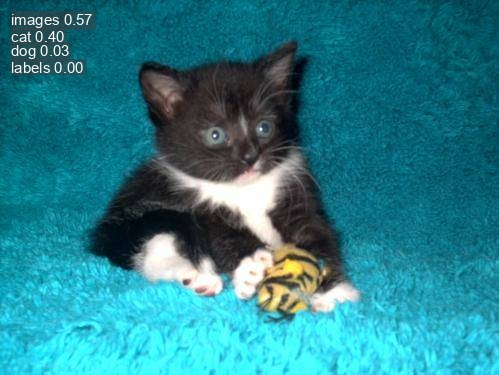

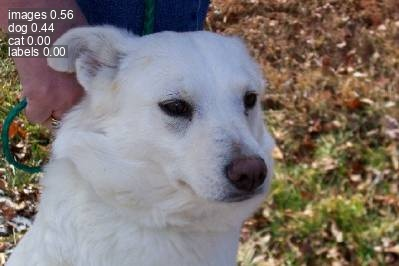

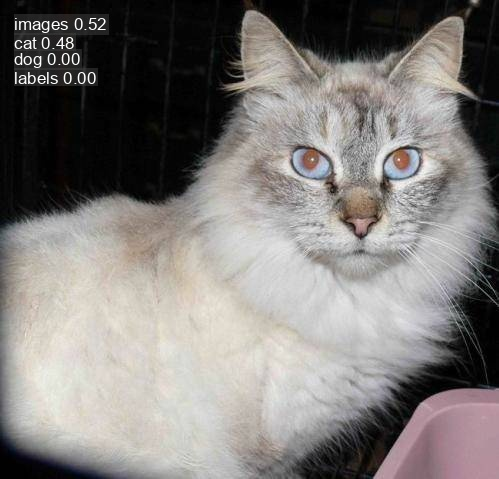

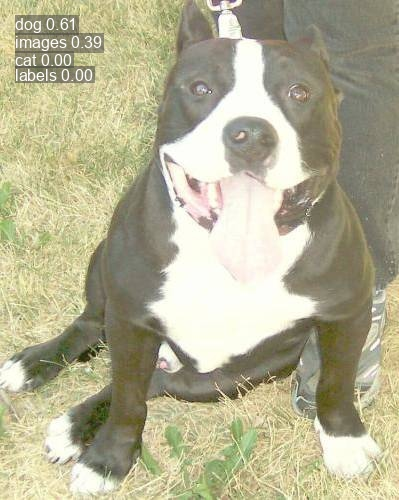

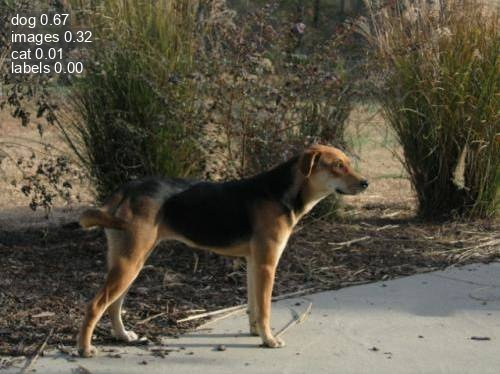

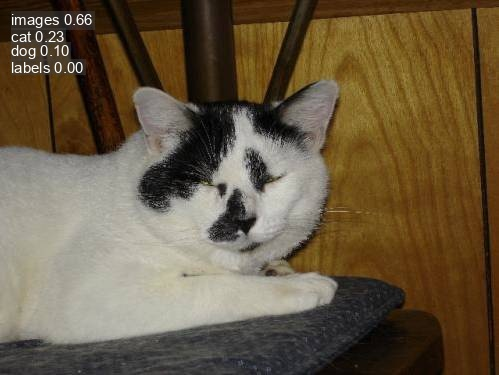

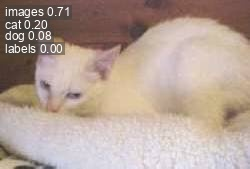

In [21]:
from IPython.display import Image, display
import glob
import os

output_path = "/content/runs/classify/predict"

images = glob.glob(output_path + "/*.jpg")

for img in images[:10]:
    display(Image(filename=img, width=400))

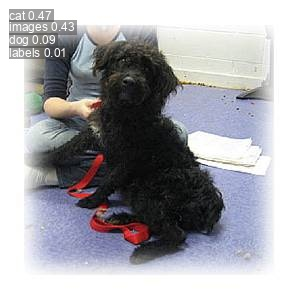

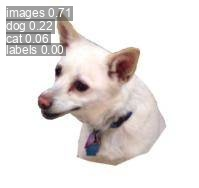

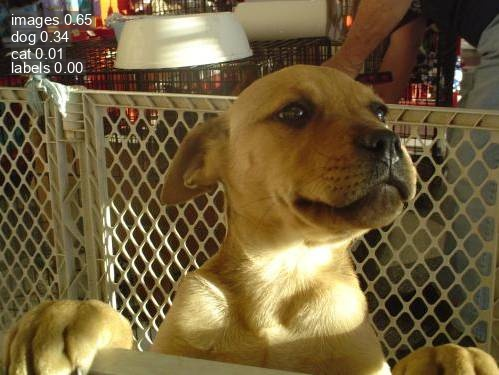

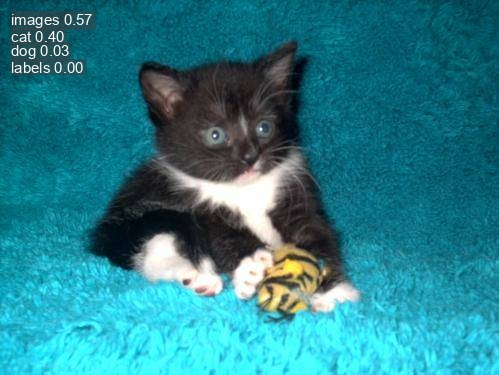

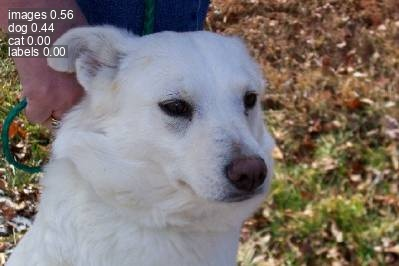

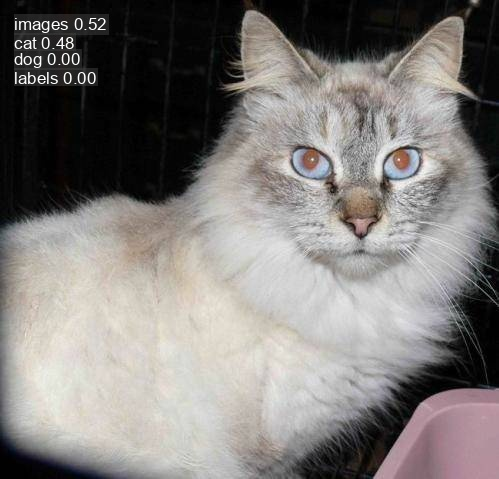

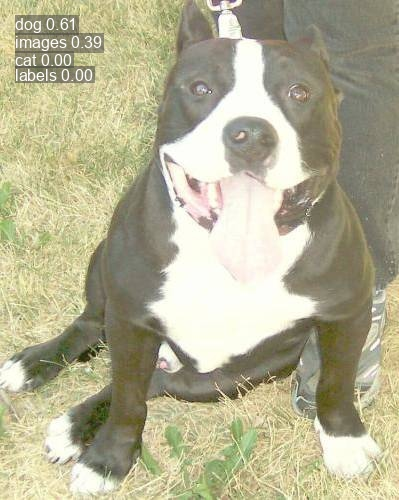

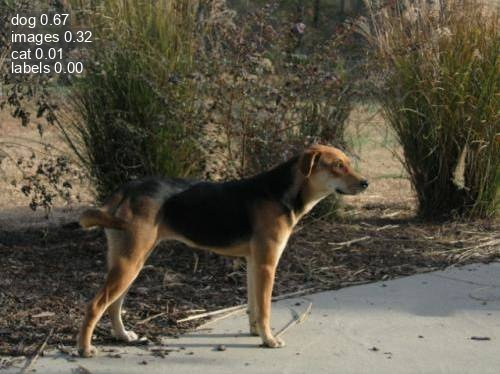

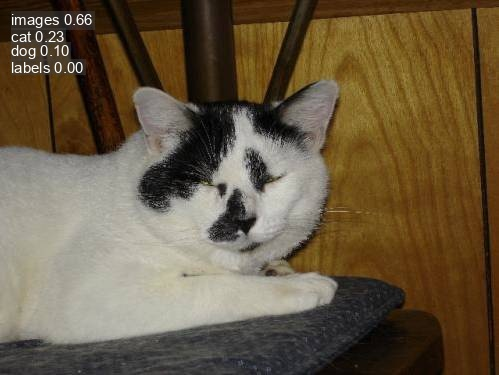

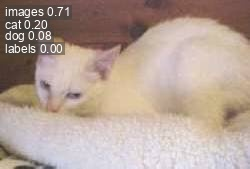

In [22]:
from IPython.display import Image, display
import glob
import os

output_path = "/content/runs/classify/predict"

images = glob.glob(output_path + "/*.jpg")

for img in images[:10]:
    display(Image(filename=img, width=400))

In [23]:
from ultralytics import YOLO
from IPython.display import Image, display
import os
import glob

model = YOLO(
    "runs/classify/dog_cat_classifier/weights/best.pt"
)

for cls in ["cat", "dog"]:

    print(f"\n===== {cls.upper()} PREDICTIONS =====")

    results = model.predict(
        source=os.path.join(base, "test", cls),
        save=True,
        conf=0.25
    )

    for result in results:
        display(
            Image(
                filename=result.path,
                width=300
            )
        )

        print("Actual:", cls)
        print("Predicted:", result.names[result.probs.top1])
        print("Confidence:", round(result.probs.top1conf.item() * 100, 2), "%")

Output hidden; open in https://colab.research.google.com to view.